# AST 326: Asteroid Lab 
### Tutorial 2 - How to Find the Source Positions
- Primary Authors: Jacob Taylor, Bethany Ludwig
- Last Revision: January 2024
  
### Overview of the Lab:  

The goal of this lab is to measure the proper motion of an asteroid using 4 observations. To do this, we will first need to determine the asteroids position in each observation using astrometry. If you'd like a head start, feel free to practice on the NGC7331 galaxy. 

This lab is broken into four tutorials: 

1) Familiarize yourself with the data and how to obtain clean sky images (Last Week)

2) Find stars in your cleaned images and cross correlate them with a catalog (Today)

3) Plate solve your images and compute asteroid positions (Jan 22)
  
4) Decomposing affine transformations (optional part of the lab) and open work session (Jan 29)

### Step 1: You should have reduced data for each of the obervations last week. Import one of those now. 

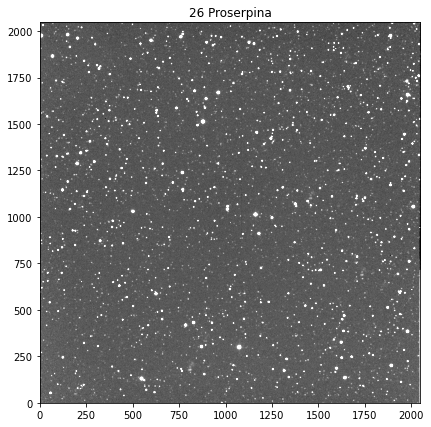

In [2]:
# Set the path to one of your reduced files
from astropy.io import fits
data = fits.open('Data/26Proserpina/Cleaned/cleaned_20120119.fits')[0].data

# Take a look at your image
import matplotlib.pyplot as plt
from astropy.visualization import ZScaleInterval

plt.figure(figsize=(7,7))
vmin,vmax = ZScaleInterval().get_limits(data)
plt.imshow(data, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('26 Proserpina');


## Step 2: Find the center of a star

You can approach this in several different ways. One is to use the centroid equation.
A centroid is the 'arithmetic mean' of a geometric shape. In this context, it is just a weigthed sum of the pixel values. The easiest way to conceptualize the centroid from a physicists perspective is to treat the pixel values as a mass distribution where the centroid is the center of mass.

$$<x> = \frac{\Sigma_{i}x_i I_i}{\Sigma_i I_i}$$
$$<y> = \frac{\Sigma_{i}y_i I_i}{\Sigma_i I_i}$$

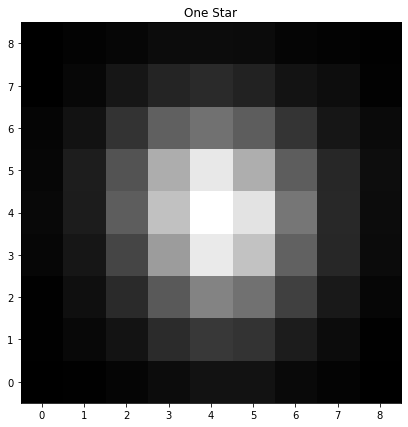

In [3]:
# Lets look at one star for right now 
# You'll want to apply your algorithm to the entire image eventually 
star = data[50:59,52:61]

plt.figure(figsize=(7,7))
vmin,vmax = ZScaleInterval().get_limits(star)
plt.imshow(star, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('One Star');

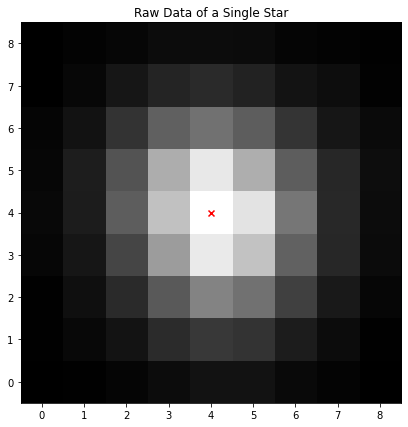

In [4]:
import numpy as np 

# Write a basic centroid equation for this region
# You can use the one you wrote before
xx, yy = np.meshgrid(np.arange(star.shape[1]), np.arange(star.shape[0])) 
x = np.sum(xx * star) / np.sum(star) 
y = np.sum(yy * star) / np.sum(star) 

# Lets take a look at how we did 
plt.figure(figsize=(7,7))
plt.imshow(star, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('Raw Data of a Single Star')
plt.scatter(x,y,marker='x',color='red')

That's not bad! The reason this worked though is because of how well we centered on the star.
If you include too much of a background, your results might vary.
Try playing around with the dimensions we set for this star to see what I mean.

What are some things we can do to improve our centroiding?
- Smooth things out with a gaussian kernel?
- Try to remove the background? 
- Use our first approximation and repeat the process with a smaller window? 
- Apply a weighting to our algorithm?
- Use a different algorithm? Maybe the circumscribed circle equation?  

These are all valid things to try! How fast and accurate can you get your algorithm to be?

Our next challenge will be applying this to the entire image.

## Step 3: Find the center of all of your stars

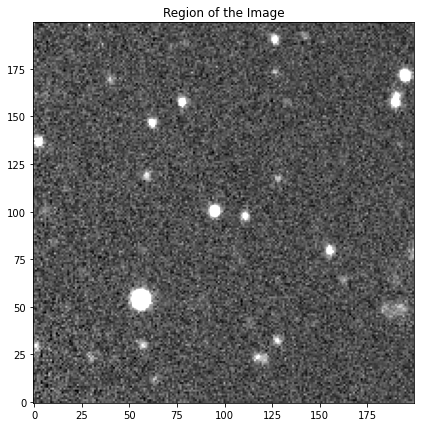

In [31]:
# Let's try to find the brightest points in the image so we can center on each star algorithmically 
# I'm going to use a smaller version of the image to speed things up for the tutorial
# You'll want to use the full image for your final project
region = data[0:200,0:200]

vmin,vmax = ZScaleInterval().get_limits(region)
plt.figure(figsize=(7,7))
plt.imshow(region, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('Region of the Image');

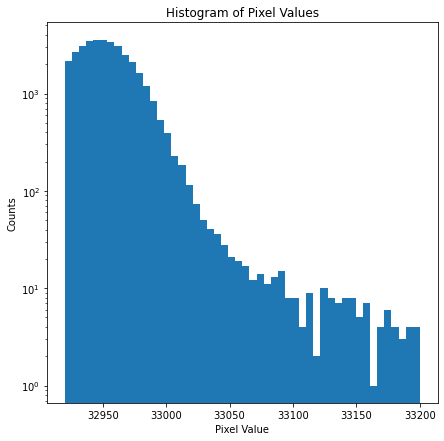

In [32]:
# What threshold should we use to determine what is a bright point?
# Lets take a look at the histogram of the image
plt.figure(figsize=(7,7))
# Play around with the range to get a sense of what pixel values are most common or rare
plt.hist(region.flatten(),bins=50,range=(32920,33200))
plt.yscale('log')
plt.xlabel('Pixel Value')
plt.ylabel('Counts')
plt.title('Histogram of Pixel Values');

8 pixels seem to be saturated


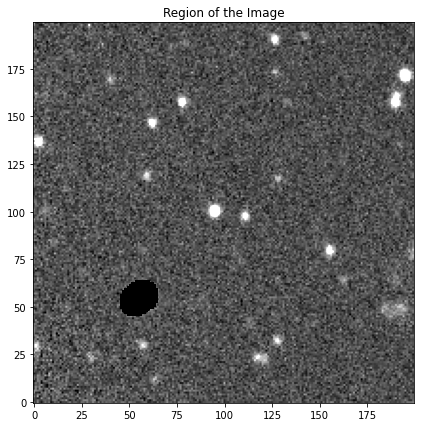

In [33]:
# Optional, but it may be helpful to also mask out the oversaturated bright stars as they are likely foreground anyway.
# Pick a value that would only include the **saturated** stars
# You could also do a percentile instead of a hard value
saturated_threshhold = 
saturated_positions = np.where(region > saturated_threshhold)
print(f"{len(saturated_positions[0])} pixels seem to be saturated")

# Create a mask
mask = np.ones_like(region)
# Decide how big of an aperture you want to use to mask out the saturated stars
width = 

for pix in saturated_positions:
    # Create a circle around that pixel 
    yy, xx = np.mgrid[:region.shape[0], :region.shape[1]]
    circle = (xx - pix[1])**2 + (yy - pix[0])**2
    circle = circle < width**2
    # Set the pixels inside the circle to 0
    mask[circle] = 0

# Multiply the mask by your data
masked_region = region * mask

# Take a look
plt.figure(figsize=(7,7))
plt.imshow(masked_region, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('Region of the Image');

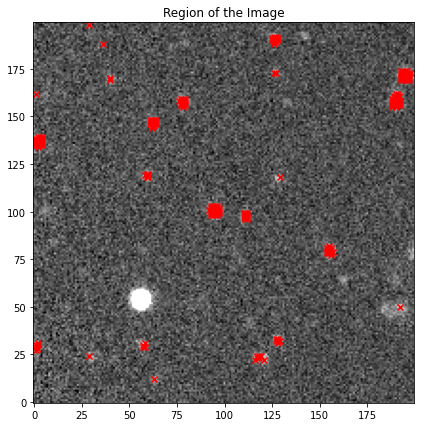

In [34]:
# Now we want to find the brightest points in the image for the normal stars so we can center them and find their centroids
# Pick a value from the histogram we just plotted that you think may exclude the background but include the stars
threshhold =

# Find pixel positions where the intensity of the pixel is greater than the threshhold
bright_points = np.where(masked_region > threshhold)

# Remember to be careful of how indexing works in python
# The first index is the y position, the second index is the x position
xs = bright_points[1]
ys = bright_points[0]

plt.figure(figsize=(7,7))
plt.imshow(region, vmin=vmin, vmax=vmax, cmap='gray', origin='lower')
plt.title('Region of the Image');
plt.scatter(xs,ys,marker='x',color='red',label='Bright Points')

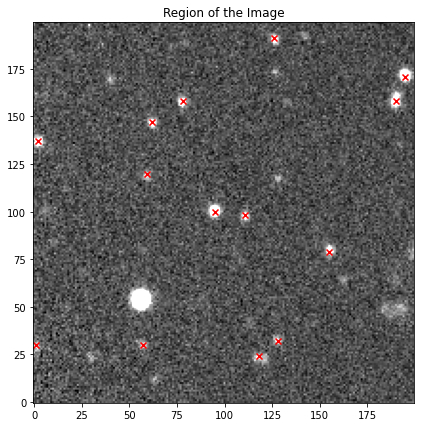

In [35]:
# It would be a good idea to not have to calculate the centroid for every single one of those red points.
# That would be redundant, and it would take a long time to run.
# Find a way to reduce the number of points you need to one per star.


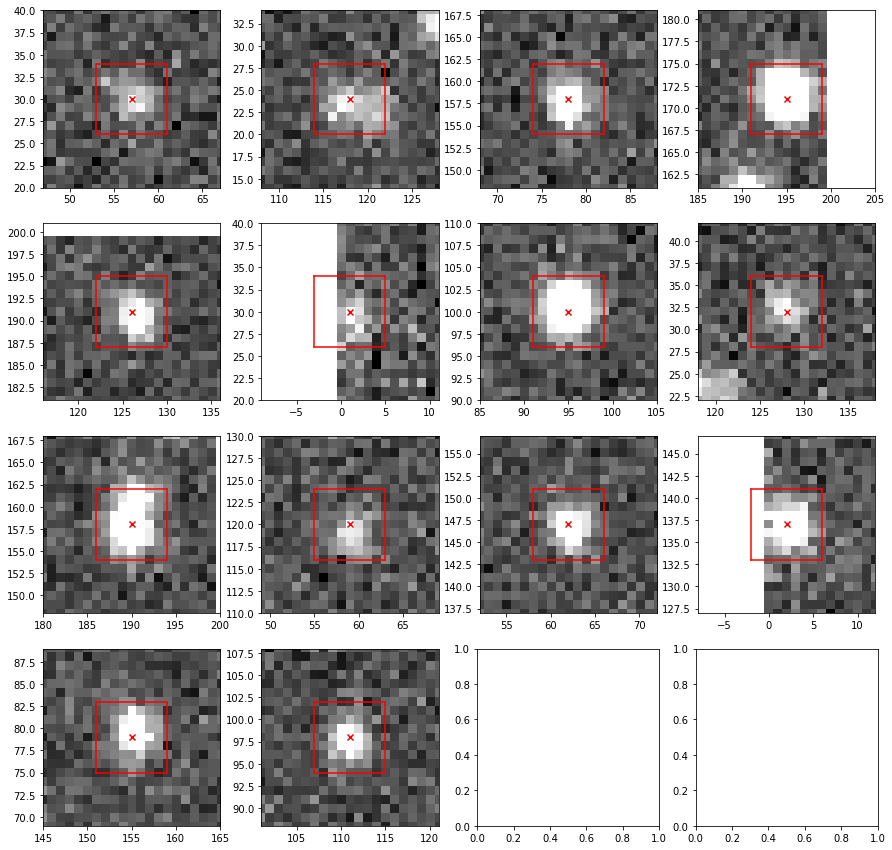

In [36]:
# Now we want to zoom in on each star and find the centroid of each one
# Create a box around each star and calculate the centroid

What do you think about the result? Do things seem centered to you? How could we have improved things? How would we account for the positional error? 

Don't forget to apply what we learned to the entire image, do each observation, and save your source positions for the next notebook. 

In [37]:
# Save your centroids to a file

import pandas as pd 
# Make a dictionary of the positions of the centroids
centroids = {'x':cent_xs,'y':cent_ys}
# Save the dictionary to a file
my_catalog = pd.DataFrame(centroids)
my_catalog.to_csv('Data/26Proserpina/Centroids/20120119.csv',index=False)
my_catalog

,x,y
0,56.500570,29.500593
1,117.501245,23.499652
2,77.501231,157.500363
3,194.502072,170.505295
4,125.501442,190.500058
5,94.501932,99.503851
6,127.500454,31.500938
7,189.501231,157.501373
8,58.500825,119.499449
9,61.501474,146.500355
